# **Logistic Regression Model**

Unlike Linear Regression which is used for predicting continuous values, **Logistic Regression** is a classification algorithm used to predict the probability of a binary event (0 or 1).

**Import necessary libraries**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn.metrics as metrics
import statsmodels.api as sm
import sklearn.model_selection as model_selection

In [3]:

X = np.array([1, 2, 3, 4, 5])
Y = np.array([0, 1, 0, 1, 1])

df = pd.DataFrame({
    "hour_study": X,
    "Score": Y
})

display(df)

,hour_study,Score
0,1,0
1,2,1
2,3,0
3,4,1
4,5,1


**Build the Simple Logistic Regression model**

In [4]:
X_model = sm.add_constant(X)
logistic_model = sm.Logit(Y, X_model).fit()

print(logistic_model.summary())

Optimization terminated successfully.
         Current function value: 0.484393
         Iterations 6
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                    5
Model:                          Logit   Df Residuals:                        3
Method:                           MLE   Df Model:                            1
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.2803
Time:                        15:10:26   Log-Likelihood:                -2.4220
converged:                       True   LL-Null:                       -3.3651
Covariance Type:            nonrobust   LLR p-value:                    0.1696
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         -2.6486      2.806     -0.944      0.345      -8.148       2.851
x1             1.0904      0.

In [5]:

# Predicted probabilities
Y_pred = logistic_model.predict(X_model)
print(Y_pred)

[0.17391068 0.38515236 0.65083011 0.84723996 0.94286688]


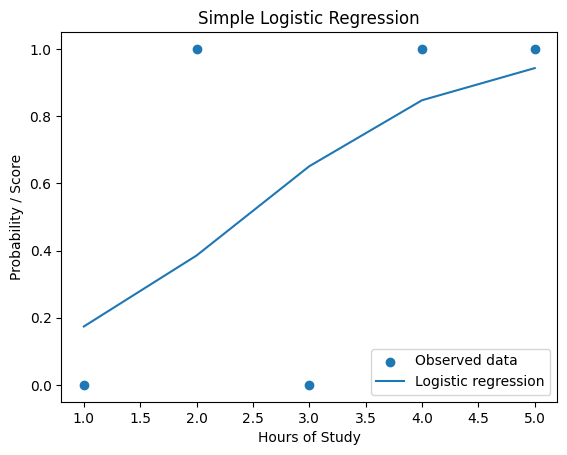

In [6]:
# Plot
plt.scatter(X, Y, label="Observed data")
plt.plot(X, Y_pred, label="Logistic regression")

plt.xlabel("Hours of Study")
plt.ylabel("Probability / Score")
plt.title("Simple Logistic Regression")
plt.legend()
plt.show()

### **Evaluation Metrics for Logistic Regression**

To evaluate our classification model's performance, we can compute metrics like accuracy, precision, recall, F1-score, and display a confusion matrix.

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Predicted probabilities
Y_pred = logistic_model.predict(X_model)

# Convert probabilities to classes
Y_pred_class = (Y_pred >= 0.5).astype(int)

print("Predicted probabilities:", Y_pred)
print("Predicted classes:", Y_pred_class)

#  Accuracy
accuracy = accuracy_score(Y, Y_pred_class)
print("Accuracy:", accuracy)

#  Precision
precision = precision_score(Y, Y_pred_class)
print("Precision:", precision)

#  Recall
recall = recall_score(Y, Y_pred_class)
print("Recall:", recall)

#  F1-score
f1 = f1_score(Y, Y_pred_class)
print("F1-score:", f1)

Predicted probabilities: [0.17391068 0.38515236 0.65083011 0.84723996 0.94286688]
Predicted classes: [0 0 1 1 1]
Accuracy: 0.6
Precision: 0.6666666666666666
Recall: 0.6666666666666666
F1-score: 0.6666666666666666



# **Multiple Logistic Regression**


Let's apply Multiple logistic regression to the real dataset: `/content/Multiple_logistic_Regression.csv`.
 We will load the data, define a target variable, preprocess the features, fit the model, and evaluate it.

In [8]:
from google.colab import files
upload=files.upload()

Saving Multiple_logistic_Regression.csv to Multiple_logistic_Regression.csv


In [25]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
from sklearn.model_selection import train_test_split
from sklearn import metrics

In [10]:
df=pd.read_csv("Multiple_logistic_Regression.csv",sep=";")
df.head()

,Study_Hours,Attendance_Percent,Assignments_Completed,Previous_Score,Sleep_Hours,Pass
0,9.87,70.7,10.0,66.7,7.1,1
1,11.63,76.7,9.5,64.4,6.2,1
2,7.49,89.9,8.9,57.8,7.1,1
3,1.17,76.8,7.3,60.4,5.1,0
4,3.61,82.0,6.4,71.2,6.3,1


In [11]:
print(df.shape)

(1000, 6)


In [12]:
x=df[['Study_Hours','Attendance_Percent','Assignments_Completed','Previous_Score','Sleep_Hours']]
y=df['Pass']


In [13]:
x.head()

,Study_Hours,Attendance_Percent,Assignments_Completed,Previous_Score,Sleep_Hours
0,9.87,70.7,10.0,66.7,7.1
1,11.63,76.7,9.5,64.4,6.2
2,7.49,89.9,8.9,57.8,7.1
3,1.17,76.8,7.3,60.4,5.1
4,3.61,82.0,6.4,71.2,6.3


In [14]:
y.head()

,Pass
0,1
1,1
2,1
3,0
4,1


#**Build the Multiple Logistic Regression model**

In [42]:
#  Split the Data (70% Train / 30% Test)

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.3,       # 30% for testing
    random_state=42,     # reproducibility
    stratify=y           # keep class proportions
)

print(f"Train size: {x_train.shape[0]} samples")
print(f"Test  size: {x_test.shape[0]} samples")
print(f"Train distribution:\n{y_train.value_counts()}")
print(f"Test distribution:\n{y_test.value_counts()}")

Train size: 700 samples
Test  size: 300 samples
Train distribution:
Pass
1    664
0     36
Name: count, dtype: int64
Test distribution:
Pass
1    285
0     15
Name: count, dtype: int64


In [43]:
#  Add Constant (Intercept Term)

x_train_const = sm.add_constant(x_train)
x_test_const = sm.add_constant(x_test)


In [44]:
#  Train the Model on Training Data Only

log_model = sm.Logit(y_train, x_train_const).fit()
print(log_model.summary())

Optimization terminated successfully.
         Current function value: 0.141482
         Iterations 9
                           Logit Regression Results                           
Dep. Variable:                   Pass   No. Observations:                  700
Model:                          Logit   Df Residuals:                      694
Method:                           MLE   Df Model:                            5
Date:                Sun, 11 Oct 2026   Pseudo R-squ.:                  0.3020
Time:                        16:44:16   Log-Likelihood:                -99.038
converged:                       True   LL-Null:                       -141.89
Covariance Type:            nonrobust   LLR p-value:                 5.355e-17
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                   -14.8608      2.784     -5.338      0.000     -20.317      -9.

In [41]:
#  Predict on Test Data
y_pred_proba = log_model.predict(x_test_const)
y_pred_class = np.where(y_pred_proba > 0.5, 1, 0)

In [45]:
#  Evaluate on Test Data
print("\n" + "="*50)
print("Model Evaluation on Test Set")
print("="*50)


Model Evaluation on Test Set


### **Evaluation Metrics for Multiple Logistic Regression**

To evaluate our classification model's performance, we can compute metrics like accuracy, precision, recall, F1-score, and display a confusion matrix.

In [37]:
# Confusion Matrix
cm = metrics.confusion_matrix(y_test, y_pred_class)
print("Confusion Matrix:\n", cm)

# Extract TN, FP, FN, TP
TN, FP, FN, TP = cm.ravel()
print(f"\nTN = {TN}  (Actual 0 -> Predicted 0)")
print(f"FP = {FP}  (Actual 0 -> Predicted 1)")
print(f"FN = {FN}  (Actual 1 -> Predicted 0)")
print(f"TP = {TP}  (Actual 1 -> Predicted 1)")

Confusion Matrix:
 [[  1  14]
 [  2 283]]

TN = 1  (Actual 0 -> Predicted 0)
FP = 14  (Actual 0 -> Predicted 1)
FN = 2  (Actual 1 -> Predicted 0)
TP = 283  (Actual 1 -> Predicted 1)


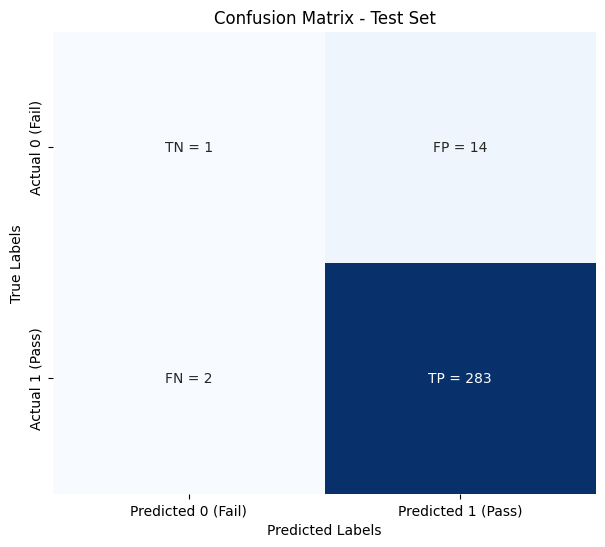

In [39]:
#  Plot Confusion Matrix

labels = np.array([
    [f"TN = {TN}", f"FP = {FP}"],
    [f"FN = {FN}", f"TP = {TP}"]
])

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False,
            xticklabels=['Predicted 0 (Fail)', 'Predicted 1 (Pass)'],
            yticklabels=['Actual 0 (Fail)', 'Actual 1 (Pass)'])
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix - Test Set')
plt.show()


In [38]:
# Metrics
accuracy = metrics.accuracy_score(y_test, y_pred_class)
precision = metrics.precision_score(y_test, y_pred_class)
recall = metrics.recall_score(y_test, y_pred_class)
f1 = metrics.f1_score(y_test, y_pred_class)

print(f"\nAccuracy:  {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-Score:  {f1:.4f}")


Accuracy:  0.9467
Precision: 0.9529
Recall:    0.9930
F1-Score:  0.9725


In [40]:
#  Compare Train vs Test (Overfitting Check)
# ============================================
y_pred_train_class = np.where(
    log_model.predict(x_train_const) > 0.5, 1, 0
)
train_acc = metrics.accuracy_score(y_train, y_pred_train_class)
test_acc = accuracy

print("\n" + "="*50)
print("Overfitting Check")
print("="*50)
print(f"Train Accuracy: {train_acc:.4f}")
print(f"Test  Accuracy: {test_acc:.4f}")
print(f"Difference:     {abs(train_acc - test_acc):.4f}")

if abs(train_acc - test_acc) < 0.05:
    print("Good model - no significant overfitting")
else:
    print("Warning: large gap -> possible overfitting")


Overfitting Check
Train Accuracy: 0.9500
Test  Accuracy: 0.9467
Difference:     0.0033
Good model - no significant overfitting
